# RIKUY_DEEP: deteccion de defectos en piezas de fundicion

Flujo: ingesta y versionado del dataset (data-v1) -> CNN (cnn-v1) -> ResNet50 (resnet-v1) -> comparacion en test -> exportacion a TensorFlow.js.

Decisiones de diseno:

El dataset de Kaggle ya viene augmentado: no se aplica augmentation durante el entrenamiento.
data-v1 es el dataset tal como se descarga. El redimensionado ocurre en tf.data, no se duplica en disco.
Clase positiva (1) = defecto. El modelo devuelve P(defecto).
Validacion se usa para early stopping y umbral; test solo para el reporte final.

In [1]:
%pip install -q kagglehub dvc dvc-gdrive tensorflowjs

## LIBRERIAS

In [2]:
import hashlib
import json
import os
import shutil
import subprocess
import time
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from datetime import datetime, timezone
from pathlib import Path
from PIL import Image
from google.colab import drive
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,confusion_matrix, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from tensorflow.keras import Model, layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator , load_img ,img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense, Conv2D, MaxPooling2D

## CONFIGURACIÓN KAGGLE Y GOOGLE DRIVE

In [3]:
drive.mount('/content/drive')

DATA_VERSION, CNN_VERSION, RESNET_VERSION = 'data-v1', 'cnn-v1', 'resnet-v1'
KAGGLE_DATASET = 'ravirajsinh45/real-life-industrial-dataset-of-casting-product'
IMAGE_EXTENSIONS = {'.jpeg', '.jpg', '.png'}

DRIVE_ROOT = Path('/content/drive/MyDrive')
PROJECT_DIR = DRIVE_ROOT / 'RIKUY_DEEP'
REPO_DIR = DRIVE_ROOT / 'ColabNotebooks' / 'RIKUY_DEEP_G2'
DATA_DIR = PROJECT_DIR / 'data'
RAW_DATA = DATA_DIR / 'casting_data'
REPO_DATA_DIR = REPO_DIR / 'data'
REMOTE_DIR = REPO_DIR / 'dvc_remote'
REGISTRY_DIR = PROJECT_DIR / 'model_registry'
EXPORT_DIR = PROJECT_DIR / 'exports'
SPLITS_CSV = PROJECT_DIR / 'splits.csv'

for directory in (PROJECT_DIR, DATA_DIR, RAW_DATA, REPO_DIR, REGISTRY_DIR, EXPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)
print(f'Proyecto y fuente de datos: {PROJECT_DIR}')
print(f'Datos crudos: {RAW_DATA}')
print(f'Repositorio: {REPO_DIR}')
print(f'Datos DVC: {REPO_DATA_DIR}')
print(f'Remoto DVC en Google Drive: {REMOTE_DIR}')
print(f'Registro de modelos: {REGISTRY_DIR}')
print(f'Modelos exportados: {EXPORT_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto y fuente de datos: /content/drive/MyDrive/RIKUY_DEEP
Datos crudos: /content/drive/MyDrive/RIKUY_DEEP/data/casting_data
Repositorio: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
Datos DVC: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data
Remoto DVC en Google Drive: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/dvc_remote
Registro de modelos: /content/drive/MyDrive/RIKUY_DEEP/model_registry
Modelos exportados: /content/drive/MyDrive/RIKUY_DEEP/exports


## Descargando el dataset

In [4]:
if not (RAW_DATA / 'def_front').exists() or not (RAW_DATA / 'ok_front').exists():
    print("Descargando dataset desde Kaggle con kagglehub...")
    path = Path(kagglehub.dataset_download(KAGGLE_DATASET))

    # Localizar la carpeta que contiene directamente las clases
    candidates = [
        path / 'casting_512x512' / 'casting_512x512',
        path / 'casting_512x512',
        path
    ]
    source_dir = next((c for c in candidates if (c / 'def_front').exists() and (c / 'ok_front').exists()), None)

    if source_dir is None:
        raise FileNotFoundError(f"No se encontró la carpeta 'casting_512x512' con las clases en {path}")

    print(f"Copiando imágenes 512x512 desde {source_dir} hacia {RAW_DATA}...")
    shutil.copytree(source_dir, RAW_DATA, dirs_exist_ok=True)
    print("Copia finalizada.")
else:
    print(f"ℹEl dataset 512x512 ya existe en {RAW_DATA}")
# Verificación y conteo de imágenes (Criterio de aceptación HU04)
num_def = len(list((RAW_DATA / 'def_front').glob('*.*')))
num_ok = len(list((RAW_DATA / 'ok_front').glob('*.*')))
total = num_def + num_ok

ℹEl dataset 512x512 ya existe en /content/drive/MyDrive/RIKUY_DEEP/data/casting_data


## Versionando el dataset

In [5]:
REPO_DATA_DIR.mkdir(parents=True, exist_ok=True)

In [16]:
import json
import shlex
import shutil
import subprocess
from dataclasses import dataclass, field
from pathlib import Path

class DVCSyncError(RuntimeError):
    """Error controlado durante la sincronización de datos con DVC."""


@dataclass
class SyncResult:
    dataset_dir: Path
    dvc_file: Path
    created_version: bool = False
    first_version: bool = False
    pulled: bool = False
    warnings: list = field(default_factory=list)

    def __str__(self):
        estado = ('primera versión' if self.first_version
                  else 'nueva versión' if self.created_version
                  else 'sin cambios')
        return f'[{estado}] {self.dataset_dir}'


def find_dvc_root(start):
    """Devuelve la raíz del repo DVC que contiene `start`, o None."""
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / '.dvc').is_dir():
            return candidate
    return None


def _run(cmd, cwd, step, check=True, timeout=None):
    try:
        proc = subprocess.run(cmd, cwd=cwd, text=True, capture_output=True, timeout=timeout)
    except FileNotFoundError:
        raise DVCSyncError(f'[{step}] Comando no encontrado: {cmd[0]!r}. ¿Está instalado?')
    except subprocess.TimeoutExpired:
        raise DVCSyncError(f'[{step}] Timeout ({timeout}s): {shlex.join(cmd)}')
    if check and proc.returncode != 0:
        raise DVCSyncError(
            f'[{step}] Falló (código {proc.returncode}): {shlex.join(cmd)}\n'
            f'{proc.stderr.strip() or proc.stdout.strip()}'
        )
    return proc


def sync_dataset_with_dvc(
    raw_data,
    repo_dir,
    dataset_name='casting_data',
    track_name=None,        # lo que DVC rastrea (ej. 'data')
    dest_subpath=None,      # destino de rsync dentro de repo_dir (ej. 'data/casting_data')
    legacy_subdir='data',   # None para desactivar el reparo de layout
    mirror_exact=False,
    pull_timeout=1800,
    rsync_timeout=3600,
    verbose=True,
):
    log = print if verbose else (lambda *a, **k: None)

    raw_data = Path(raw_data)
    repo_dir = Path(repo_dir)
    track_name = track_name or dataset_name
    legacy_dir = repo_dir / legacy_subdir / dataset_name if legacy_subdir else None
    tracked_dir = repo_dir / (dest_subpath or dataset_name)
    dvc_file = repo_dir / f'{track_name}.dvc'
    result = SyncResult(dataset_dir=tracked_dir, dvc_file=dvc_file)

    # 0) Validaciones previas
    if not raw_data.is_dir():
        raise DVCSyncError(f'RAW_DATA no existe o no es carpeta: {raw_data}')
    if not any(raw_data.iterdir()):
        raise DVCSyncError(f'RAW_DATA está vacía: {raw_data}')
    for tool in ('dvc', 'rsync', 'git'):
        if shutil.which(tool) is None:
            raise DVCSyncError(f'No se encontró {tool!r} en el PATH.')

    repo_dir.mkdir(parents=True, exist_ok=True)
    dvc_root = find_dvc_root(repo_dir)
    if dvc_root is None:
        raise DVCSyncError(
            f'{repo_dir} no está dentro de ningún repo DVC (no se encontró .dvc/ '
            f'en esta carpeta ni en sus padres). Ejecuta `dvc init` en la raíz del proyecto.'
        )
    log(f'Repo DVC detectado en: {dvc_root}')

    # 1) Reparar layout anterior (solo si legacy_subdir está activo)
    if legacy_dir is not None and legacy_dir.is_dir():
        if tracked_dir.exists():
            result.warnings.append(
                f'Existen ambas rutas ({legacy_dir} y {tracked_dir}); no se movió nada.'
            )
        else:
            try:
                shutil.move(str(legacy_dir), str(tracked_dir))
                log(f'Layout reparado: {legacy_dir} -> {tracked_dir}')
            except OSError as e:
                raise DVCSyncError(f'[layout] No se pudo mover el dataset: {e}')

    # 2) Traer versión registrada (no crítico)
    if dvc_file.exists():
        try:
            _run(['dvc', 'pull', dvc_file.name], repo_dir, 'pull', timeout=pull_timeout)
            result.pulled = True
            log('dvc pull: OK')
        except DVCSyncError as e:
            result.warnings.append(f'dvc pull falló, se continúa con datos locales:\n{e}')
            log(f'AVISO: {result.warnings[-1]}')

    # 3) Sincronizar desde RAW_DATA
    tracked_dir.mkdir(parents=True, exist_ok=True)
    rsync_cmd = ['rsync', '-ah']
    if mirror_exact:
        rsync_cmd.append('--delete')
    rsync_cmd += [f'{raw_data}/', f'{tracked_dir}/']
    _run(rsync_cmd, repo_dir, 'rsync', timeout=rsync_timeout)
    log(f'rsync: OK ({"espejo exacto" if mirror_exact else "aditivo"})')

    # 4) Decidir si hay versión nueva
    if not dvc_file.exists():
        log('Primera versión: no existe el .dvc')
        _run(['dvc', 'add', track_name], repo_dir, 'dvc add')
        result.first_version = result.created_version = True
    else:
        proc = _run(['dvc', 'status', dvc_file.name, '--json'], repo_dir, 'dvc status')
        try:
            changes = json.loads(proc.stdout or '{}')
        except json.JSONDecodeError as e:
            raise DVCSyncError(f'[dvc status] Salida JSON inválida: {e}\n{proc.stdout}')
        if changes:
            log('Hay cambios: se registra una nueva versión')
            _run(['dvc', 'add', track_name], repo_dir, 'dvc add')
            result.created_version = True
        else:
            log('Datos idénticos a la versión existente; no se crea versión nueva')

    if result.created_version:
        log(f'Siguiente paso: git add {dvc_file.name} .gitignore && '
            f'git commit -m "data: update {track_name}" && dvc push')
    return result


# --- Uso: repo_dir es la RAÍZ, no la carpeta data ---
ROOT = Path('/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2')

try:
    res = sync_dataset_with_dvc(
        raw_data=RAW_DATA,
        repo_dir=ROOT,
        dataset_name='casting_data',
        track_name='data',                  # coincide con data.dvc
        dest_subpath='data/casting_data',   # destino del rsync
        legacy_subdir=None,                 # sin reparo de layout
        mirror_exact=False,
    )
    print(res)
    for w in res.warnings:
        print('AVISO:', w)
except DVCSyncError as e:
    print(f'ERROR de sincronización:\n{e}')

Repo DVC detectado en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
dvc pull: OK
rsync: OK (aditivo)
Datos idénticos a la versión existente; no se crea versión nueva
[sin cambios] /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/casting_data


In [17]:
%cd {REPO_DIR}

/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2


In [18]:
def publish_version(res, repo_dir, remote_dir, remote_name='drive',
                    track_name='data', commit=True, push_timeout=3600):
    """
    Configura el remoto y publica (push + git add/commit) SOLO si hubo versión nueva.
    Si res.created_version es False, termina de inmediato sin tocar nada.
    """
    repo_dir, remote_dir = Path(repo_dir), Path(remote_dir)

    # Salida rápida: no hubo cambios en el dataset.
    if not res.created_version:
        print('Sin cambios en el dataset: no se hace push ni commit.')
        return False

    # 1) Remoto (idempotente)
    remote_dir.mkdir(parents=True, exist_ok=True)
    out = _run(['dvc', 'remote', 'list'], repo_dir, 'remote list').stdout.splitlines()
    existe = any(l.split() and l.split()[0] == remote_name for l in out)
    if existe:
        _run(['dvc', 'remote', 'modify', remote_name, 'url', str(remote_dir)], repo_dir, 'remote modify')
        _run(['dvc', 'remote', 'default', remote_name], repo_dir, 'remote default')
    else:
        _run(['dvc', 'remote', 'add', '--default', remote_name, str(remote_dir)], repo_dir, 'remote add')

    # 2) Subir al remoto (solo se transfiere lo nuevo)
    _run(['dvc', 'push', f'{track_name}.dvc'], repo_dir, 'dvc push', timeout=push_timeout)
    print('dvc push: OK')

    # 3) Git: staging y commit solo si hay algo que confirmar
    _run(['git', 'add', f'{track_name}.dvc', '.gitignore', '.dvc/config'], repo_dir, 'git add')
    staged = _run(['git', 'diff', '--cached', '--quiet'], repo_dir, 'git diff', check=False)
    if staged.returncode == 0:
        print('Nada nuevo en staging: no se hace commit.')
    elif commit:
        _run(['git', 'commit', '-m', f'data: update {track_name}'], repo_dir, 'git commit')
        print('git commit: OK')
    return True


# --- Uso ---
try:
    res = sync_dataset_with_dvc(
        raw_data=RAW_DATA, repo_dir=ROOT, dataset_name='casting_data',
        track_name='data', dest_subpath='data/casting_data',
        legacy_subdir=None, mirror_exact=False,
    )
    print(res)
    publish_version(res, ROOT, REMOTE_DIR)
except DVCSyncError as e:
    print(f'ERROR:\n{e}')

Repo DVC detectado en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
dvc pull: OK
rsync: OK (aditivo)
Datos idénticos a la versión existente; no se crea versión nueva
[sin cambios] /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/casting_data
Sin cambios en el dataset: no se hace push ni commit.


## Preprocesamiento de imagenes | Data augmentation

In [19]:
%cd /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2

/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2


In [24]:
!git fetch origin


From https://github.com/d-a-b-o/RIKUY_DEEP_G2
 * [new branch]      RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a -> origin/RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a


In [25]:
!git switch RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a

M	RIKUY_DEEP_G2.ipynb
branch 'RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a' set up to track 'origin/RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a'.
Switched to a new branch 'RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a'


In [29]:
# HU06: EDA, preprocesamiento compartido a 400x400, augmentation solo en train y versionado DVC.
from pathlib import Path
from collections import Counter
import hashlib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display
from sklearn.model_selection import train_test_split

ROOT = Path('/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2')
DATA_DIR = ROOT / 'data'
RAW_DIR = DATA_DIR / 'casting_data'
PROCESSED_DIR = DATA_DIR / 'processed_data_400x400'
TARGET_SIZE = (400, 400)
CLASSES = ('def_front', 'ok_front')
SEED = 42

branch = subprocess.check_output(['git', 'branch', '--show-current'], cwd=ROOT, text=True).strip()
assert branch == 'RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a', f'Rama inesperada: {branch}'
assert RAW_DIR.is_dir(), f'No existe el dataset DVC: {RAW_DIR}. Ejecuta primero la celda de sincronizacion DVC.'

In [30]:
# Especificacion compartida: decodificar como RGB, resize bilinear a 400x400 y escalar RGB a [0,1].
# Equivalencia TF.js: tf.image.resizeBilinear(rgb, [400,400]) seguido de div(255).
PREPROCESSING_SOURCE = '''"""Preprocesamiento compartido HU06 para fundición.
Entrada: imagen decodificada RGB. Resize bilinear a 400x400. RGB float32 en [0,1].
TensorFlow.js: tf.image.resizeBilinear(rgb, [400, 400]).div(255).
Augmentation solo se activa con training=True en el conjunto train.
"""
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps, ImageEnhance

TARGET_SIZE = (400, 400)


def preprocess_image(image):
    """Acepta ruta, PIL.Image o ndarray RGB; retorna float32 (400,400,3) en [0,1]."""
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    elif isinstance(image, np.ndarray):
        image = Image.fromarray(np.asarray(image, dtype=np.uint8))
    image = image.convert("RGB").resize(TARGET_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32) / 255.0


def augment_training_image(image, seed=None):
    """Rotacion, flip horizontal y brillo; llamar solo con ejemplos de train."""
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    image = image.convert("RGB")
    rng = np.random.default_rng(seed)
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)
    image = image.rotate(float(rng.uniform(-12.0, 12.0)), resample=Image.Resampling.BILINEAR,
                         expand=False, fillcolor=(0, 0, 0))
    return ImageEnhance.Brightness(image).enhance(float(rng.uniform(0.85, 1.15)))


def make_tf_dataset(paths, labels, training=False, batch_size=32, seed=42):
    """Dataset tf.data; flip/rotacion/brillo ocurren unicamente si training=True."""
    import tensorflow as tf
    paths = [str(p) for p in paths]
    labels = np.asarray(labels, dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    rotation = tf.keras.layers.RandomRotation(0.04, fill_mode="reflect", seed=seed)

    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, TARGET_SIZE, method="bilinear")
        image = tf.cast(image, tf.float32) / 255.0
        if training:
            image = tf.image.random_flip_left_right(image, seed=seed)
            image = rotation(image, training=True)
            image = tf.image.random_brightness(image, max_delta=0.15, seed=seed)
            image = tf.clip_by_value(image, 0.0, 1.0)
        return image, label

    return ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)
'''
(ROOT / 'ml').mkdir(parents=True, exist_ok=True)
(ROOT / 'ml' / 'preprocessing.py').write_text(PREPROCESSING_SOURCE, encoding='utf-8')

2613

In [31]:
# Inventario + estadisticas de las imagenes originales; no modifica data/casting_data.
records, unreadable = [], []
for class_name in CLASSES:
    class_dir = RAW_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f'Falta la clase: {class_dir}')
    for path in sorted(p for p in class_dir.rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}):
        try:
            with Image.open(path) as image:
                width, height, fmt, mode = image.width, image.height, image.format, image.mode
                rgb = np.asarray(image.convert('RGB'), dtype=np.float32)
            luminance = 0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]
            records.append({'path': path, 'class_name': class_name, 'label': int(class_name == 'def_front'),
                            'width': width, 'height': height, 'format': fmt, 'source_mode': mode,
                            'mean_intensity': float(luminance.mean()), 'std_intensity': float(luminance.std()),
                            'r_mean': float(rgb[..., 0].mean()), 'g_mean': float(rgb[..., 1].mean()),
                            'b_mean': float(rgb[..., 2].mean())})
        except Exception as exc:
            unreadable.append((str(path), str(exc)))

eda = pd.DataFrame(records)
if eda.empty:
    raise RuntimeError(f'No se encontraron imagenes legibles en {RAW_DIR}')
counts = eda['class_name'].value_counts().reindex(CLASSES, fill_value=0)
print(f'Rama: {branch} | Imagenes legibles: {len(eda)} | No legibles: {len(unreadable)}')
print('\nDistribucion por clase:')
display(counts.rename('imagenes').to_frame().assign(porcentaje=lambda x: (100*x['imagenes']/len(eda)).round(2)))
print('\nEstadisticas por clase (dimensiones originales, intensidad luminosa 0-255 y medias RGB):')
display(eda.groupby('class_name')[['width', 'height', 'mean_intensity', 'std_intensity', 'r_mean', 'g_mean', 'b_mean']]
        .agg(['min', 'median', 'max']).round(2))
print('\nDimensiones originales mas frecuentes:')
display(eda.groupby(['width', 'height']).size().sort_values(ascending=False).head(10).rename('imagenes').to_frame())

Rama: RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a | Imagenes legibles: 1300 | No legibles: 0

Distribucion por clase:


,imagenes,porcentaje
class_name,,
def_front,781,60.08
ok_front,519,39.92



Estadisticas por clase (dimensiones originales, intensidad luminosa 0-255 y medias RGB):


width             height             mean_intensity          \
             min median  max    min median  max            min  median   
class_name                                                               
def_front    512  512.0  512    512  512.0  512         115.58  136.65   
ok_front     512  512.0  512    512  512.0  512         123.52  149.56   

                   std_intensity  ...         r_mean                  g_mean  \
               max           min  ...    max     min  median     max     min   
class_name                        ...                                          
def_front   172.15         48.13  ...  75.28  115.58  136.65  172.15  115.58   
ok_front    169.79         54.62  ...  70.94  123.52  149.56  169.79  123.52   

                            b_mean                  
            median     max     min  median     max  
class_name                                          
def_front   136.65  172.15  115.58  136.65  172.15  
ok_front    149.56  169.79  123.52  149.56  169.79  

[2 rows x 21 columns]


Dimensiones originales mas frecuentes:


,,imagenes
width,height,
512,512,1300


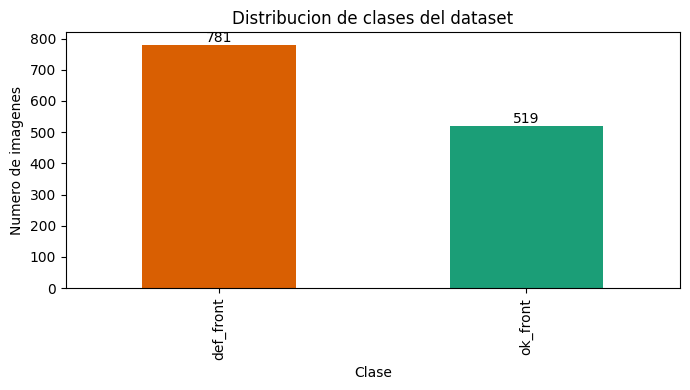

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind='bar', color=['#d95f02', '#1b9e77'], ax=ax)
ax.set(title='Distribucion de clases del dataset', xlabel='Clase', ylabel='Numero de imagenes')
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()

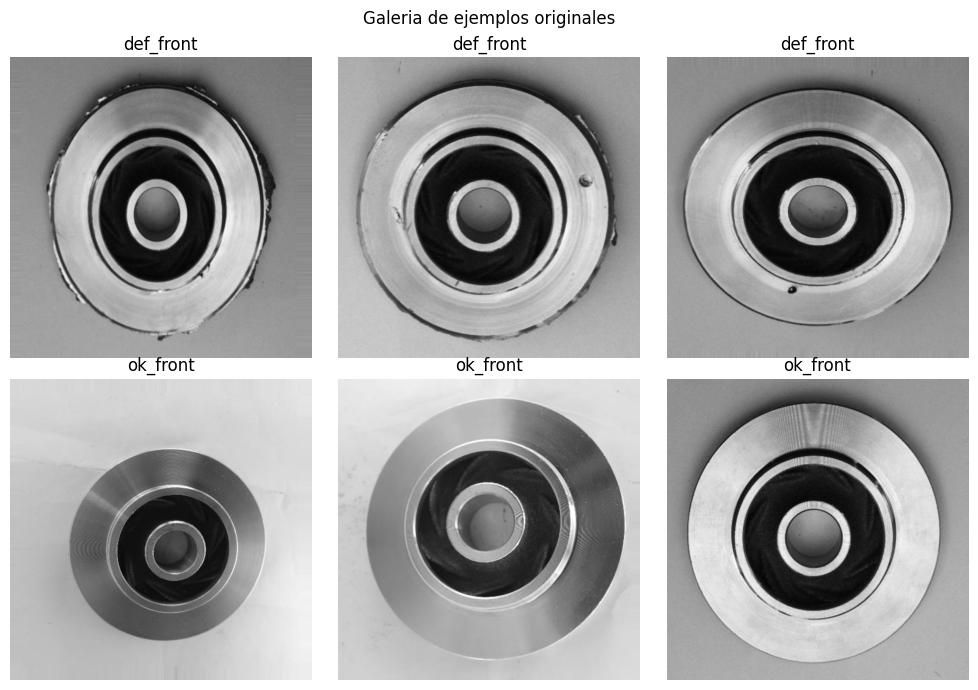

In [33]:
# Galeria equilibrada de ejemplos originales (sin modificar el dataset).
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 7))
for row_i, class_name in enumerate(CLASSES):
    examples = eda.loc[eda.class_name == class_name, 'path'].head(3).tolist()
    for col_i, ax in enumerate(axes[row_i]):
        ax.axis('off')
        if col_i < len(examples):
            with Image.open(examples[col_i]) as image:
                ax.imshow(image.convert('RGB'))
            ax.set_title(class_name)
plt.suptitle('Galeria de ejemplos originales'); plt.tight_layout(); plt.show()


In [34]:
# Conclusiones calculadas, sin asumir balance ni dimensiones que no hayan sido observadas.
majority, minority = int(counts.max()), int(counts.min())
print('\nConclusiones EDA:')
print(f'- Desbalance mayoritaria/minoritaria: {majority}/{minority} = {majority/minority:.2f}:1.')
print(f'- Rango de dimensiones: {eda.width.min()}x{eda.height.min()} a {eda.width.max()}x{eda.height.max()}.')
print(f'- Rango de intensidad media: {eda.mean_intensity.min():.1f}-{eda.mean_intensity.max():.1f} (escala 0-255).')
if unreadable:
    print(f'- Se excluyeron {len(unreadable)} archivos ilegibles del inventario; no se borraron.')
print('- Se conserva RGB; normalizacion definida como float32 / 255, rango [0,1].')
print('- El notebook indica que la fuente ya contiene augmentation. Se parte primero train/validacion/test y la augmentation adicional queda restringida a train.')
print('- Revisar posibles imagenes casi duplicadas entre particiones antes del entrenamiento para prevenir leakage.')


Conclusiones EDA:
- Desbalance mayoritaria/minoritaria: 781/519 = 1.50:1.
- Rango de dimensiones: 512x512 a 512x512.
- Rango de intensidad media: 115.6-172.1 (escala 0-255).
- Se conserva RGB; normalizacion definida como float32 / 255, rango [0,1].
- El notebook indica que la fuente ya contiene augmentation. Se parte primero train/validacion/test y la augmentation adicional queda restringida a train.
- Revisar posibles imagenes casi duplicadas entre particiones antes del entrenamiento para prevenir leakage.


In [35]:
# Split estratificado 70/15/15, semilla fija. La fuente permanece intacta.
train_df, remainder_df = train_test_split(eda, test_size=0.30, random_state=SEED, stratify=eda['label'])
val_df, test_df = train_test_split(remainder_df, test_size=0.50, random_state=SEED, stratify=remainder_df['label'])
splits = {'train': train_df.reset_index(drop=True), 'validation': val_df.reset_index(drop=True), 'test': test_df.reset_index(drop=True)}

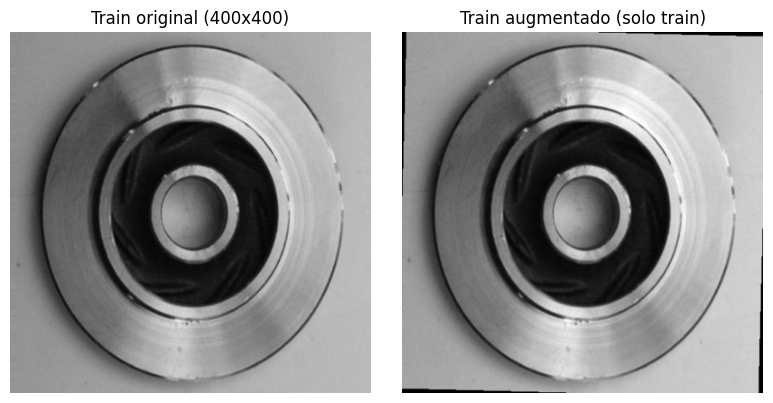

In [36]:
# Previsualizar augmentation con una muestra de train: flip/rotacion/brillo.
from ml.preprocessing import preprocess_image, augment_training_image, make_tf_dataset
sample_path = splits['train'].iloc[0]['path']
original_preview = preprocess_image(sample_path)
augmented_preview = preprocess_image(augment_training_image(sample_path, seed=SEED))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_preview); axes[0].set_title('Train original (400x400)')
axes[1].imshow(augmented_preview); axes[1].set_title('Train augmentado (solo train)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [37]:
# Guardar versiones RGB 400x400 y manifiesto bajo la ruta solicitada.
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
manifest_rows = []
for split_name, split_df in splits.items():
    for row in split_df.itertuples(index=False):
        target = PROCESSED_DIR / split_name / row.class_name / f'{row.path.stem}.jpg'
        target.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(row.path) as image:
            image.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR).save(target, 'JPEG', quality=95, optimize=True)
        manifest_rows.append({'path': target.relative_to(ROOT).as_posix(), 'split': split_name,
                              'class_name': row.class_name, 'label_defect': int(row.label), 'sample_type': 'original'})

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(PROCESSED_DIR / 'manifest.csv', index=False)
eda.drop(columns=['path']).to_csv(PROCESSED_DIR / 'eda_image_stats.csv', index=False)

In [38]:
# Verificacion de tamaño final de todos los ejemplos exportados.
for path in PROCESSED_DIR.glob('*/*/*'):
    if path.is_file() and path.suffix.lower() == '.jpg':
        with Image.open(path) as image:
            if image.size != TARGET_SIZE:
                raise AssertionError(f'Tamano inesperado: {path} -> {image.size}')
print('\nParticiones procesadas (solo originales; augmentation se aplica al generador de train):')
display(manifest.groupby(['split', 'class_name']).size().rename('imagenes').to_frame())
print(f'Imagenes procesadas: {len(manifest)} | Todas con tamano {TARGET_SIZE[0]}x{TARGET_SIZE[1]} | Carpeta: {PROCESSED_DIR}')


Particiones procesadas (solo originales; augmentation se aplica al generador de train):


imagenes
split      class_name          
test       def_front        117
           ok_front          78
train      def_front        547
           ok_front         363
validation def_front        117
           ok_front          78

Imagenes procesadas: 1300 | Todas con tamano 400x400 | Carpeta: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/processed_data_400x400


In [39]:
# Crear un batch para demostrar el generador; el argumento training=True activa flip/rotacion/brillo.
train_paths = [ROOT / p for p in manifest.loc[manifest.split == 'train', 'path']]
train_labels = manifest.loc[manifest.split == 'train', 'label_defect'].to_numpy()
val_paths = [ROOT / p for p in manifest.loc[manifest.split == 'validation', 'path']]
val_labels = manifest.loc[manifest.split == 'validation', 'label_defect'].to_numpy()
train_batch_images, train_batch_labels = next(iter(make_tf_dataset(train_paths, train_labels, training=True, batch_size=8, seed=SEED)))
val_batch_images, val_batch_labels = next(iter(make_tf_dataset(val_paths, val_labels, training=False, batch_size=8, seed=SEED)))
assert tuple(train_batch_images.shape[1:]) == (400, 400, 3) and tuple(val_batch_images.shape[1:]) == (400, 400, 3)
print(f'Generador train: {train_batch_images.shape}; generador validation sin augmentation: {val_batch_images.shape}.')

Generador train: (8, 400, 400, 3); generador validation sin augmentation: (8, 400, 400, 3).


In [40]:
# DVC ya rastrea la carpeta data completa mediante data.dvc; refrescar el puntero mantiene raw + processed en un solo output.
remote_list = subprocess.check_output(['dvc', 'remote', 'list'], cwd=ROOT, text=True)
if not any(line.split() and line.split()[0] == 'drive' for line in remote_list.splitlines()):
    raise RuntimeError('No esta configurado el remoto DVC drive; no se modifica el puntero.')
subprocess.run(['dvc', 'add', 'data'], cwd=ROOT, check=True)
subprocess.run(['dvc', 'push', 'data.dvc'], cwd=ROOT, check=True)
# Dejar listos para revision el notebook, el modulo y el puntero. No se crea commit ni se hace push a GitHub.
subprocess.run(['git', 'add', 'RIKUY_DEEP_G2.ipynb', 'ml/preprocessing.py', 'data.dvc', '.gitignore'], cwd=ROOT, check=True)
print('\nVersion DVC enviada al remoto Google Drive. Cambios Git preparados, sin commit ni push:')
print(subprocess.check_output(['git', 'status', '--short', '--branch'], cwd=ROOT, text=True))


Version DVC enviada al remoto Google Drive. Cambios Git preparados, sin commit ni push:
## RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a...origin/RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a
M  RIKUY_DEEP_G2.ipynb
M  data.dvc
A  ml/preprocessing.py
?? ml/__pycache__/



In [41]:
!git status


On branch RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a
Your branch is up to date with 'origin/RIKDP-17-hu06-analisis-exploratorio-preprocesamiento-y-a'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   RIKUY_DEEP_G2.ipynb
	modified:   data.dvc
	new file:   ml/preprocessing.py

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   RIKUY_DEEP_G2.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	ml/__pycache__/



In [ ]:
!git add RIKU